# Structural identifiability of the rate laws

Stigter and Molenaar (2015): at $q$ random parameter vectors (every free parameter log-uniform in its bounds) the
exact sensitivity matrix of the 9 reaction rates at the fitted states of the 22 conditions is computed with CasADi,

$$S_{ij} = \frac{\theta_j}{\mathrm{median}_c |v_r|}\,\frac{\partial v_i}{\partial \theta_j},$$

the $q$ matrices are stacked and decomposed by SVD. A singular value below `structural_tol` times the largest is a
structural zero: a combination of parameters that leaves every rate unchanged, at every parameter vector. In the
Noor et al. (2013) rate law only the products of the substrate (and product) constants of a reaction enter, so these
zeros are expected; the selection fixes one parameter per zero (`parameter_selection.ipynb`, step 1).

This notebook recomputes the spectrum at the stage-0 fit (all 37 free) and at the final fit. Nothing is written.

In [1]:
import os
import sys
import json
import logging
import warnings

HERE = os.getcwd()
REPO = os.path.dirname(HERE) if os.path.basename(HERE) == "notebooks" else HERE
for path in (os.path.join(REPO, "notebooks"), os.path.join(REPO, "src")):
    if path not in sys.path:
        sys.path.insert(0, path)

import settings  # noqa: F401  (pins BLAS / OpenMP to one thread before numpy is loaded)
from paths import resolve_out

OUT = resolve_out(os.environ.get("HK_OUT") or settings.METHOD["out_dir"])
RUN = os.environ.get("HK_RUN", "0") == "1"

warnings.filterwarnings("ignore")
logging.getLogger("pyomo").setLevel(logging.ERROR)
print("OUT :", OUT)
print("RUN :", RUN, "(False: load the saved results of OUT; True: compute and save into OUT)")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

from estimation.anchors import load_point, read_anchor
from identifiability.structural import RateLaws, condition_states, stacked_sensitivity_matrix, singular_spectrum
from identifiability.rules import largest_loading

OUT : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/results/flux_model
RUN : False (False: load the saved results of OUT; True: compute and save into OUT)


In [2]:
# Settings of the method (defaults from settings/method.csv)
params = settings.default_params()
params["n_jobs"] = int(os.environ.get("HK_N_JOBS", params["n_jobs"]))
params

{'n_starts': 50,
 'seed': 0,
 'structural_q': 10,
 'structural_tol': 1e-10,
 'rank_tol': 0.0001,
 'corr_threshold': 0.9,
 'lr_alpha': 0.95,
 'bootstrap_n': 5000,
 'bootstrap_ci_ratio': 10.0,
 'bootstrap_local_starts': 5,
 'bootstrap_local_span': 1.0,
 'profile_points': 30,
 'profile_span': 1.0,
 'profile_extra_starts': 3,
 'profile_extra_span': 1.0,
 'bootstrap_profile_seeds': 3,
 'n_jobs': 10,
 'out_dir': 'results/flux_model'}

In [3]:
rate_laws = RateLaws()
stage0 = load_point(read_anchor(os.path.join(OUT, "stage0")))
free0 = list(stage0.free_params)
S0 = stacked_sensitivity_matrix(rate_laws, stage0.full_theta(), condition_states(stage0), free0, params)
ratio0, Vt0 = singular_spectrum(S0)
final = load_point(read_anchor(os.path.join(OUT, "final")))
S1 = stacked_sensitivity_matrix(rate_laws, final.full_theta(), condition_states(final), list(final.free_params), params)
ratio1, _ = singular_spectrum(S1)
print("stage 0: %d free, %d structural zeros" % (len(free0), int(np.sum(ratio0 < params["structural_tol"]))))
print("final  : %d free, %d structural zeros" % (len(final.free_params), int(np.sum(ratio1 < params["structural_tol"]))))

stage 0: 37 free, 8 structural zeros
final  : 14 free, 0 structural zeros


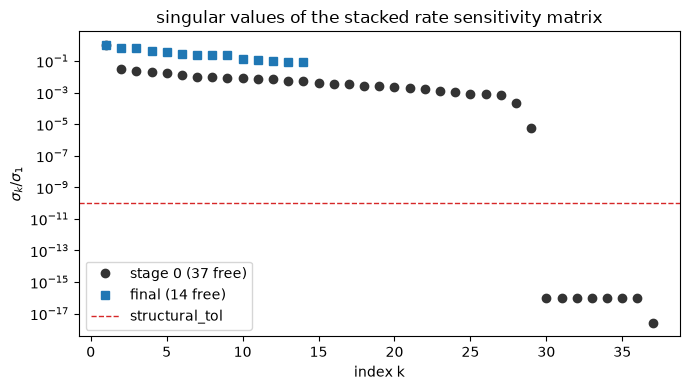

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(np.arange(1, len(ratio0) + 1), ratio0, "o", color="0.2", label="stage 0 (%d free)" % len(ratio0))
ax.semilogy(np.arange(1, len(ratio1) + 1), ratio1, "s", color="tab:blue", label="final (%d free)" % len(ratio1))
ax.axhline(params["structural_tol"], color="tab:red", ls="--", lw=1, label="structural_tol")
ax.set_xlabel("index k")
ax.set_ylabel(r"$\sigma_k / \sigma_1$")
ax.legend()
ax.set_title("singular values of the stacked rate sensitivity matrix")
fig.tight_layout()
plt.show()

## Parameters of the structural zeros at stage 0

For each zero singular value, the parameters with a loading above 0.1 in its right singular vector (any basis of the
null space is valid; the selection works on one direction at a time and recomputes the SVD after every fix).

In [5]:
rows = []
for k in np.where(ratio0 < params["structural_tol"])[0]:
    loadings = pd.Series(Vt0[k], index=free0)
    large = loadings[loadings.abs() > 0.1].sort_values(key=np.abs, ascending=False)
    rows.append({"k": k + 1, "sigma_ratio": ratio0[k], "parameters": ", ".join("%s %+.2f" % (p, v) for p, v in large.items())})
pd.DataFrame(rows)

,k,sigma_ratio,parameters
0,30,9.675966e-17,"Ks_3pg_7 -0.59, Ks_atp_7 +0.59, Kp_g3p_4 -0.30..."
1,31,9.675966e-17,"Kp_g3p_4 -0.41, Kp_dhap_4 +0.41, Ks_3pg_7 +0.3..."
2,32,9.675966e-17,"Kp_nadh_6 -0.41, Kp_pgp_6 +0.41, Ks_nad_6 +0.3..."
3,33,9.675966e-17,"Ks_adp_7 +0.54, Ks_pgp_7 -0.54, Kp_nadh_6 +0.4..."
4,34,9.675966e-17,"Kp_adp_3 +0.55, Kp_fbp_3 -0.55, Kp_g3p_4 -0.32..."
5,35,9.675966e-17,"Ks_nad_6 -0.57, Ks_g3p_6 +0.54, Kp_pgp_6 +0.30..."
6,36,9.675966e-17,"Ks_pi_6 -0.81, Ks_g3p_6 +0.44, Ks_nad_6 +0.37"
7,37,2.702708e-18,"Ks_f6p_3 -0.71, Ks_atp_3 +0.71"
